# Hydrogen-bond acceptors and acute toxicity: supporting machine learning

**Question:** Is an increased number of hydrogen-bond acceptors associated with greater acute toxicity?

**H0:** No association between hydrogen-bond acceptor count and acute toxicity.
**H1:** Increasing acceptor count is associated with greater acute toxicity.
`LD50` is already **−log10(LD50 in mol/kg)**: a larger score means greater toxicity.
It is never log-transformed again. Prediction errors below use these transformed units.

## Starting point and analysis plan

The repository review found completed cleaning, descriptive statistics, six main figures,
six exploratory figures, the sample-size audit and a two-sided Spearman test in
`01_data_exploration.ipynb`. `src/data_visualisation.py` already implements unadjusted
and molecular-weight/LogP-adjusted regressions with standard errors clustered by identical
SMILES. The machine-learning module was a placeholder and `results/` was empty.
Those workflows and original figures are preserved. This notebook adds diagnostics,
sensitivity checks and the requested prediction comparisons.

We use all 7,388 processed records, a fixed seed of 42, an approximately 80/20 split
**by recorded SMILES**, and five training-only folds with the same grouping. Median
imputation and linear-model scaling are fitted inside each training fold. We compare
linear regression, random forest and gradient boosting on three fixed descriptor sets.
The model family for interpretation is selected by training CV RMSE using all descriptors;
the held-out test set is used once to report all preplanned comparisons, then to inspect
permutation importance. We do not retune after inspecting test results.

**Scope:** grouping prevents identical recorded SMILES crossing partitions. It does not
canonicalise alternative SMILES or group related scaffolds, tautomers or salt forms.
Thus it is not proof that all chemically equivalent structures have been separated,
or an estimate of performance on entirely new chemical families. External validation
and mechanistic experiments are outside this project.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

# Resolve paths from either the repository root or the notebooks directory.
ROOT = Path.cwd() if (Path.cwd() / 'data').is_dir() else Path.cwd().parent
FIGURES = ROOT / 'figures'
RESULTS = ROOT / 'results'
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
SEED = 42
N_JOBS = 2
N_FOLDS = 5
raw_path = ROOT / 'data/raw/ld50-smiles-descriptors-dataset.csv'
processed_path = ROOT / 'data/processed/ld50_cleaned.csv'
input_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                for p in [raw_path, processed_path]}
df = pd.read_csv(processed_path)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=200, facecolor='white', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def interpret(text):
    display(Markdown('**Interpretation.** ' + text))

## 1. Descriptor selection, missingness and repeated structures

Use all **25 existing numerical molecular descriptors**, selected by their role rather
than their association with the outcome. `Name` and `SMILES` are identifiers, and `LD50`
is the target: none is a predictor. The descriptors cover molecular size/mass (`MolWt`,
`HeavyAtomMolWt`, `HeavyAtomCount`), lipophilicity (`MolLogP`), hydrogen bonding
(`NumHAcceptors`, `NumHDonors`), heteroatoms/rings, topology/connectivity (`BertzCT`,
`Chi*`, `Kappa3`), charge, surface area/electronic environment, and the composite `qed` score.

Some descriptors contain overlapping information. In particular, `qed` is a composite
drug-likeness descriptor that includes HBA among its inputs ([RDKit definition](https://www.rdkit.org/docs/source/rdkit.Chem.QED.html)), and acceptor count correlates with size and heteroatom count.
Removing `NumHAcceptors` tests the value of that **explicit column** beyond the retained
descriptors; it cannot remove all chemical information about acceptor groups.
No descriptor or row is selected using a test-set outcome. Retain extreme observations.

In [2]:
FEATURES = [c for c in df.select_dtypes(include='number').columns if c != 'LD50']
assert len(FEATURES) == 25
assert {'NumHAcceptors', 'MolWt', 'MolLogP'}.issubset(FEATURES)
assert not df.duplicated().any()
assert df['SMILES'].notna().all() and df['SMILES'].str.strip().ne('').all()
assert df['SMILES'].eq(df['SMILES'].str.strip()).all()
assert np.isfinite(df['LD50']).all()
assert not np.isinf(df[FEATURES].to_numpy()).any()
assert df['NumHAcceptors'].ge(0).all() and df['NumHAcceptors'].mod(1).eq(0).all()

X = df[FEATURES]
y = df['LD50']
groups = df['SMILES']
missing = X.isna().sum().rename('missing_records').to_frame()
missing.index.name = 'descriptor'
missing.to_csv(RESULTS / 'ml_missing_values.csv')

# Report repeated identifiers without removing possibly independent measurements.
duplicates = df.groupby('SMILES').agg(
    records=('LD50', 'size'), distinct_targets=('LD50', 'nunique'),
    target_min=('LD50', 'min'), target_max=('LD50', 'max'))
duplicates = duplicates.loc[duplicates['records'] > 1].copy()
duplicates['target_range'] = duplicates['target_max'] - duplicates['target_min']
duplicates.to_csv(RESULTS / 'ml_structure_duplicates.csv')
audit = pd.Series({
    'processed_records': len(df), 'numerical_predictors': len(FEATURES),
    'exact_duplicate_rows': int(df.duplicated().sum()),
    'unique_recorded_smiles': groups.nunique(),
    'repeated_smiles_beyond_first': int(groups.duplicated().sum()),
    'repeated_smiles_groups': len(duplicates),
    'records_in_repeated_smiles_groups': int(duplicates['records'].sum()),
    'rows_missing_any_predictor': int(X.isna().any(axis=1).sum()),
    'missing_predictor_cells': int(X.isna().sum().sum()),
    'existing_adjusted_complete_cases': int(df[['LD50', 'NumHAcceptors', 'MolWt', 'MolLogP']].notna().all(axis=1).sum()),
}, name='value')
audit.to_csv(RESULTS / 'ml_data_audit.csv', index_label='check')
display(audit.to_frame())
display(missing.loc[missing['missing_records'] > 0])
display(duplicates.sort_values('target_range', ascending=False).head(10))
interpret(f"All {len(df):,} records are retained for prediction. {audit['rows_missing_any_predictor']} "
          "have at least one missing descriptor, handled by training-only median imputation. "
          f"There are {groups.nunique():,} distinct recorded SMILES and {len(duplicates)} repeated groups. "
          "Different toxicity measurements for the same SMILES are retained and kept in the same partition. "
          "The earlier 7,378-record regressions excluded only the ten records missing molecular weight or LogP.")

,value
processed_records,7388
numerical_predictors,25
exact_duplicate_rows,0
unique_recorded_smiles,7341
repeated_smiles_beyond_first,47
repeated_smiles_groups,40
records_in_repeated_smiles_groups,87
rows_missing_any_predictor,65
missing_predictor_cells,71
existing_adjusted_complete_cases,7378


,missing_records
descriptor,
BertzCT,5
Chi2v,8
Chi3n,8
Chi3v,8
Chi4n,4
Chi4v,3
HeavyAtomMolWt,1
Kappa3,3
MaxPartialCharge,5


,records,distinct_targets,target_min,target_max,target_range
SMILES,,,,,
CC1(C)C(C=C(Cl)Cl)C1C(=O)OC(C#N)c1cccc(Oc2ccccc2)c1,3,3,1.920,3.860,1.940
CC(C)=CC1C(C(=O)OCc2coc(Cc3ccccc3)c2)C1(C)C,2,2,2.435,3.730,1.295
CC(C)(S)C(N)C(=O)O,2,2,1.384,2.612,1.228
C/C=C\c1ccc(OC)cc1,2,2,1.851,2.995,1.144
ClC1=C(Cl)C2(Cl)C3C4CC(C5OC45)C3C1(Cl)C2(Cl)Cl,2,2,3.998,5.104,1.106
COP(=O)(OC)O/C(=C\Cl)c1cc(Cl)c(Cl)cc1Cl,2,2,1.961,2.882,0.921
ClC1=C(Cl)C2(Cl)C3C4C=CC(C4)C3C1(Cl)C2(Cl)Cl,2,2,3.971,4.717,0.746
Nc1ccccn1,2,2,1.952,2.673,0.721
CNC(=O)Oc1ccccc1C1OC(C)C(C)O1,4,4,2.923,3.622,0.699


**Interpretation.** All 7,388 records are retained for prediction. 65 have at least one missing descriptor, handled by training-only median imputation. There are 7,341 distinct recorded SMILES and 40 repeated groups. Different toxicity measurements for the same SMILES are retained and kept in the same partition. The earlier 7,378-record regressions excluded only the ten records missing molecular weight or LogP.

## 2. Connect to the existing statistics; add sensitivity and diagnostics

The original two-sided Spearman test is retained. A positive, significant result supports
the direction of H1, but a small p-value does not imply a large effect. Here we tabulate
that reference result and the molecular-weight/LogP associations without treating these
exploratory secondary comparisons as independent confirmatory discoveries.

We reuse the existing regression function rather than implement a different estimator.
New sensitivity checks give one vote per recorded SMILES (median descriptors/target),
and examine the adjusted coefficient after omitting observations with Cook's distance
above the conventional screening value 4/n. The latter is a diagnostic sensitivity,
not a reason to clean away valid extreme compounds. All ML models still use all records.

,analysis,predictor,n,estimate,p_two_sided,groups,ci95_low,ci95_high
0,"Spearman, all available records",NumHAcceptors,7388,0.25220,0.0,NaN,NaN,NaN
1,"Spearman, all available records",MolWt,7383,0.36404,0.0,NaN,NaN,NaN
2,"Spearman, all available records",MolLogP,7383,0.24422,0.0,NaN,NaN,NaN
3,"Existing unadjusted OLS, same complete cases",NumHAcceptors,7378,0.10100,0.0,7331.0,0.08810,0.11390
4,"Existing adjusted OLS, same complete cases",NumHAcceptors,7378,0.08314,0.0,7331.0,0.06451,0.10177
5,"Spearman, median per recorded SMILES",NumHAcceptors,7341,0.25456,0.0,NaN,NaN,NaN
6,"Adjusted OLS, median per recorded SMILES",NumHAcceptors,7331,0.08515,0.0,7331.0,0.06675,0.10354
7,"Adjusted OLS, Cook screening sensitivity",NumHAcceptors,6869,0.09361,0.0,6826.0,0.07940,0.10781


Adjusted HBA VIF: 2.88; Cook screening flagged 509 of 7378 records.


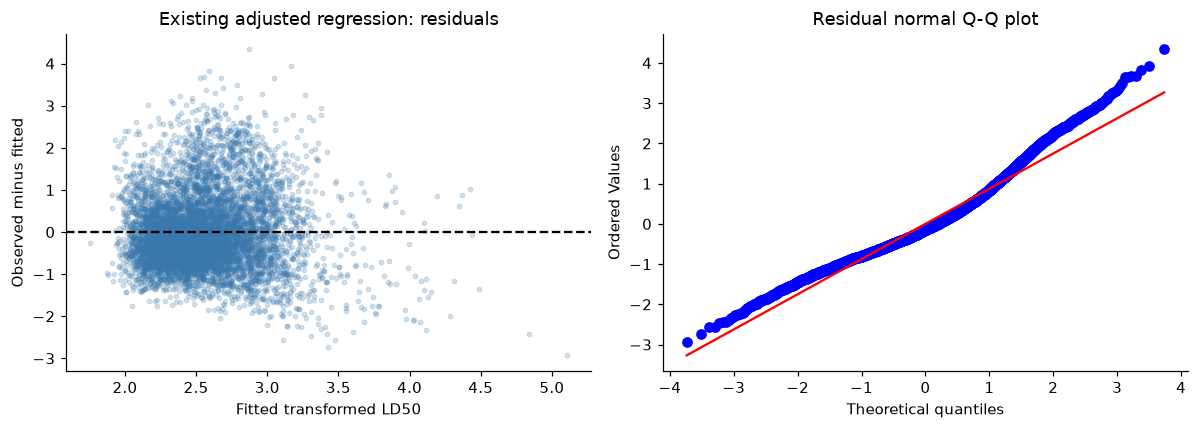

**Interpretation.** The reference HBA association is weak and positive (rho=0.252, two-sided p=1.450e-107). The existing adjusted coefficient is 0.083 transformed units per acceptor (95% CI 0.065 to 0.102). Giving one vote per SMILES yields rho=0.255. The two adjusted sensitivities give coefficients from 0.085 to 0.094; inspect their intervals above. A linear coefficient describes an average conditional association, not a universal chemical rule. Residual spread and tail departures should be assessed in these plots. The original clustered intervals allow within-SMILES dependence and unequal residual variance, but do not fix a misspecified mean relationship or eliminate confounding. The record-level Spearman p-value assumes independent records; the one-SMILES sensitivity addresses the small number of repeats.

In [3]:
sys.path.insert(0, str(ROOT / 'src'))
from data_visualisation import fit_hba_association

stat_rows = []
for feature in ['NumHAcceptors', 'MolWt', 'MolLogP']:
    sample = df[[feature, 'LD50']].dropna()
    result = stats.spearmanr(sample[feature], sample['LD50'])
    stat_rows.append({'analysis': 'Spearman, all available records', 'predictor': feature,
                     'n': len(sample), 'estimate': result.statistic, 'p_two_sided': result.pvalue})

adjustors = ['NumHAcceptors', 'MolWt', 'MolLogP']
complete = df.dropna(subset=['LD50'] + adjustors).copy()

def record_association(sample, predictors, label):
    codes, unique_smiles = pd.factorize(sample['SMILES'], sort=True)
    estimate, low, high = fit_hba_association(sample, predictors, codes)
    se = (high - low) / (2 * stats.t.ppf(0.975, len(unique_smiles) - 1))
    p = 2 * stats.t.sf(abs(estimate / se), len(unique_smiles) - 1)
    stat_rows.append({'analysis': label, 'predictor': 'NumHAcceptors', 'n': len(sample),
                     'groups': len(unique_smiles), 'estimate': estimate,
                     'ci95_low': low, 'ci95_high': high, 'p_two_sided': p})

record_association(complete, ['NumHAcceptors'], 'Existing unadjusted OLS, same complete cases')
record_association(complete, adjustors, 'Existing adjusted OLS, same complete cases')

# Median aggregation is a sensitivity only; the processed CSV is unchanged.
one_per_smiles = df.groupby('SMILES', as_index=False)[['LD50'] + adjustors].median()
unique_spearman = stats.spearmanr(one_per_smiles['NumHAcceptors'], one_per_smiles['LD50'])
stat_rows.append({'analysis': 'Spearman, median per recorded SMILES', 'predictor': 'NumHAcceptors',
                 'n': len(one_per_smiles), 'estimate': unique_spearman.statistic,
                 'p_two_sided': unique_spearman.pvalue})
record_association(one_per_smiles.dropna(), adjustors, 'Adjusted OLS, median per recorded SMILES')

# Diagnose the existing three-predictor adjusted OLS fit.
design = np.column_stack([np.ones(len(complete)), complete[adjustors]])
coefficients = np.linalg.lstsq(design, complete['LD50'], rcond=None)[0]
fitted = design @ coefficients
residuals = complete['LD50'].to_numpy() - fitted
q, _ = np.linalg.qr(design, mode='reduced')
leverage = (q ** 2).sum(axis=1)
mse = (residuals ** 2).sum() / (len(complete) - design.shape[1])
cooks = residuals ** 2 / (design.shape[1] * mse) * leverage / (1 - leverage) ** 2
influential = cooks > 4 / len(complete)
record_association(complete.loc[~influential], adjustors, 'Adjusted OLS, Cook screening sensitivity')
hba_from_covariates = LinearRegression().fit(complete[['MolWt', 'MolLogP']], complete['NumHAcceptors'])
hba_vif = 1 / (1 - hba_from_covariates.score(complete[['MolWt', 'MolLogP']], complete['NumHAcceptors']))
statistics_table = pd.DataFrame(stat_rows)
statistics_table.to_csv(RESULTS / 'association_sensitivity.csv', index=False)
display(statistics_table.round(5))
print(f'Adjusted HBA VIF: {hba_vif:.2f}; Cook screening flagged {influential.sum()} of {len(complete)} records.')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fitted, residuals, s=8, alpha=0.2, color='#3977AC')
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Fitted transformed LD50', ylabel='Observed minus fitted',
            title='Existing adjusted regression: residuals')
stats.probplot(residuals, dist='norm', plot=axes[1])
axes[1].set_title('Residual normal Q-Q plot')
save_plot(fig, 'ml_association_diagnostics.png')

rho = statistics_table.iloc[0]
adjusted = statistics_table.loc[statistics_table['analysis'].eq('Existing adjusted OLS, same complete cases')].iloc[0]
sens = statistics_table.loc[statistics_table['analysis'].str.startswith('Adjusted OLS')]
interpret(f"The reference HBA association is weak and positive (rho={rho['estimate']:.3f}, "
          f"two-sided p={rho['p_two_sided']:.3e}). The existing adjusted coefficient is "
          f"{adjusted['estimate']:.3f} transformed units per acceptor "
          f"(95% CI {adjusted['ci95_low']:.3f} to {adjusted['ci95_high']:.3f}). "
          f"Giving one vote per SMILES yields rho={unique_spearman.statistic:.3f}. "
          f"The two adjusted sensitivities give coefficients from {sens['estimate'].min():.3f} "
          f"to {sens['estimate'].max():.3f}; inspect their intervals above. "
          "A linear coefficient describes an average conditional association, not a universal chemical rule. "
          "Residual spread and tail departures should be assessed in these plots. The original clustered "
          "intervals allow within-SMILES dependence and unequal residual variance, but do not fix a misspecified "
          "mean relationship or eliminate confounding. The record-level Spearman p-value assumes independent "
          "records; the one-SMILES sensitivity addresses the small number of repeats.")

**Diagnostic reading:** The adjusted-regression residuals show a non-uniform spread, and the normal Q-Q plot has a pronounced upper-tail departure. The linear mean relationship is therefore an approximation, particularly for unusually toxic records. The two adjusted sensitivity coefficients remain positive (0.085 with one record per SMILES; 0.094 after Cook screening), consistent with the original direction.

## 3. Fix the split and training cross-validation

`GroupShuffleSplit(test_size=0.2)` holds out 20% of distinct recorded SMILES, so the
fraction of **records** can differ slightly from 20%. `GroupKFold` partitions the
training SMILES into five shuffled, reproducible folds. Explicit assertions below
check separation and coverage. Every model and descriptor comparison uses these exact
partitions. Prior exploratory work already examined the full dataset, so this is an
internal holdout evaluation, not a prospectively untouched external validation set.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups, test_groups = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(train_groups).isdisjoint(test_groups)
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(df)

cv = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, train_groups))
fold_ids = np.full(len(train_idx), -1)
for fold, (fit_idx, validation_idx) in enumerate(cv_splits):
    assert set(train_groups.iloc[fit_idx]).isdisjoint(train_groups.iloc[validation_idx])
    assert set(train_groups.iloc[fit_idx]).isdisjoint(test_groups)
    assert len(fit_idx) + len(validation_idx) == len(train_idx)
    fold_ids[validation_idx] = fold
assert np.all(fold_ids >= 0)
assert len(np.unique(np.concatenate([v for _, v in cv_splits]))) == len(train_idx)

assignments = pd.DataFrame({'processed_row': df.index, 'SMILES': groups,
                            'partition': 'test', 'validation_fold': -1})
assignments.loc[train_idx, 'partition'] = 'train'
assignments.loc[train_idx, 'validation_fold'] = fold_ids
assignments.to_csv(RESULTS / 'ml_split_assignments.csv', index=False)
print(f'Train: {len(train_idx):,} records / {train_groups.nunique():,} SMILES')
print(f'Test: {len(test_idx):,} records / {test_groups.nunique():,} SMILES ({len(test_idx)/len(df):.1%} of records)')
print('Training validation-fold sizes:', np.bincount(fold_ids).tolist())
print('SMILES overlap across test/train and every CV fit/validation split: 0')
interpret('Repeated records cannot give a model advance access to an identical recorded SMILES in a validation or test partition. '
          'Missing descriptor values are filled later, inside the model pipelines, using only each fitting partition.')

Train: 5,909 records / 5,872 SMILES
Test: 1,479 records / 1,469 SMILES (20.0% of records)
Training validation-fold sizes: [1189, 1180, 1180, 1179, 1181]
SMILES overlap across test/train and every CV fit/validation split: 0


**Interpretation.** Repeated records cannot give a model advance access to an identical recorded SMILES in a validation or test partition. Missing descriptor values are filled later, inside the model pipelines, using only each fitting partition.

## 4. Compare three models and three descriptor sets

All pipelines use median imputation; linear regression also standardises predictors
to handle their different scales. Tree models do not need scaling. The linear model
has no tuned hyperparameters. Each nonlinear model has a small four-candidate grid:

- **Random forest:** 200 trees, minimum leaf size 1 or 4; 70% or 100% of predictors considered per split.
- **Gradient boosting:** 150 or 300 trees, depth 2 or 3; learning rate 0.05 and minimum leaf size 5.

The forest's two feature-fraction settings coincide for the one-descriptor case.
Each feature set is tuned separately with the same folds and RMSE criterion, giving
reduced models a fair opportunity to fit. Only two parallel jobs are used.
A training-mean dummy regressor provides a reference beyond linear regression.

**Metrics:** R² compares squared error with predicting the evaluation-set mean (higher
is better; negative is possible). RMSE penalises large errors more than MAE (lower
is better for both). CV means and fold standard deviations describe the **selected
candidate's tuning CV**, not nested-CV performance or a confidence interval. Choosing
hyperparameters on these folds makes their CV estimates somewhat optimistic; use the
held-out test scores for the final internal performance estimate.

In [5]:
feature_sets = {
    'HBA only': ['NumHAcceptors'],
    'All descriptors': FEATURES,
    'Without HBA': [c for c in FEATURES if c != 'NumHAcceptors'],
}
model_specs = {
    'Linear Regression': (LinearRegression(), {}),
    'Random Forest': (
        RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1),
        {'model__min_samples_leaf': [1, 4], 'model__max_features': [0.7, 1.0]}),
    'Gradient Boosting': (
        GradientBoostingRegressor(learning_rate=0.05, min_samples_leaf=5, random_state=SEED),
        {'model__n_estimators': [150, 300], 'model__max_depth': [2, 3]}),
}
scoring = {'r2': 'r2', 'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'}
fitted_models = {}
comparison_rows = []
candidate_rows = []
predictions = pd.DataFrame({'processed_row': test_idx, 'SMILES': test_groups.to_numpy(),
                            'observed_LD50': y_test.to_numpy()})

def evaluate(estimator, columns):
    train_prediction = estimator.predict(X_train[columns])
    prediction = estimator.predict(X_test[columns])
    scores = {'train_r2': r2_score(y_train, train_prediction),
              'train_rmse': root_mean_squared_error(y_train, train_prediction),
              'test_r2': r2_score(y_test, prediction),
              'test_rmse': root_mean_squared_error(y_test, prediction),
              'test_mae': mean_absolute_error(y_test, prediction)}
    return scores, prediction

# The test outcomes are never passed to fit or to the hyperparameter search.
for set_name, columns in feature_sets.items():
    for model_name, (model, grid) in model_specs.items():
        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler() if model_name == 'Linear Regression' else 'passthrough'),
            ('model', model),
        ])
        search = GridSearchCV(pipeline, grid, scoring=scoring, refit='rmse',
                              cv=cv_splits, n_jobs=N_JOBS, error_score='raise',
                              pre_dispatch=N_JOBS)
        # Limit BLAS threads to avoid nested parallel oversubscription.
        with threadpool_limits(limits=1):
            search.fit(X_train[columns], y_train)
        fitted_models[(set_name, model_name)] = search.best_estimator_
        scores, prediction = evaluate(search.best_estimator_, columns)
        best = search.best_index_
        row = {'feature_set': set_name, 'model': model_name, 'n_features': len(columns), **scores,
               'best_params': json.dumps(search.best_params_, sort_keys=True)}
        for metric in scoring:
            sign = 1 if metric == 'r2' else -1
            row[f'cv_{metric}_mean'] = sign * search.cv_results_[f'mean_test_{metric}'][best]
            row[f'cv_{metric}_std'] = search.cv_results_[f'std_test_{metric}'][best]
        comparison_rows.append(row)
        predictions[f'{set_name} | {model_name}'] = prediction
        for i, params in enumerate(search.cv_results_['params']):
            candidate = {'feature_set': set_name, 'model': model_name,
                         'params': json.dumps(params, sort_keys=True), 'selected': i == best}
            for metric in scoring:
                sign = 1 if metric == 'r2' else -1
                candidate[f'cv_{metric}_mean'] = sign * search.cv_results_[f'mean_test_{metric}'][i]
                candidate[f'cv_{metric}_std'] = search.cv_results_[f'std_test_{metric}'][i]
                for fold in range(N_FOLDS):
                    candidate[f'fold_{fold}_{metric}'] = sign * search.cv_results_[f'split{fold}_test_{metric}'][i]
            candidate_rows.append(candidate)
        print(f'{set_name:16s} | {model_name:18s} | CV RMSE {row["cv_rmse_mean"]:.3f} | test RMSE {row["test_rmse"]:.3f}', flush=True)

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RESULTS / 'ml_model_comparison.csv', index=False)
pd.DataFrame(candidate_rows).to_csv(RESULTS / 'ml_cv_search.csv', index=False)
full_results = comparison.loc[comparison['feature_set'].eq('All descriptors')].copy()
best_name = full_results.loc[full_results['cv_rmse_mean'].idxmin(), 'model']
test_best_name = full_results.loc[full_results['test_rmse'].idxmin(), 'model']
best_row = full_results.loc[full_results['model'].eq(best_name)].iloc[0]
best_model = fitted_models[('All descriptors', best_name)]

# A constant baseline is fitted only to the training targets.
dummy = DummyRegressor(strategy='mean').fit(np.zeros((len(y_train), 1)), y_train)
dummy_prediction = dummy.predict(np.zeros((len(y_test), 1)))
dummy_metrics = {'test_r2': r2_score(y_test, dummy_prediction),
                 'test_rmse': root_mean_squared_error(y_test, dummy_prediction),
                 'test_mae': mean_absolute_error(y_test, dummy_prediction)}
predictions['Training mean baseline'] = dummy_prediction
predictions.to_csv(RESULTS / 'ml_test_predictions.csv', index=False)
display(full_results[['model', 'test_r2', 'test_rmse', 'test_mae',
                      'cv_r2_mean', 'cv_rmse_mean', 'cv_rmse_std', 'cv_mae_mean', 'best_params']].round(4))
print('Training-mean baseline:', dummy_metrics)
print('Selected by training CV:', best_name, '| Lowest held-out RMSE:', test_best_name)

HBA only         | Linear Regression  | CV RMSE 0.925 | test RMSE 0.916


HBA only         | Random Forest      | CV RMSE 0.916 | test RMSE 0.915


HBA only         | Gradient Boosting  | CV RMSE 0.915 | test RMSE 0.913


All descriptors  | Linear Regression  | CV RMSE 0.818 | test RMSE 0.799


All descriptors  | Random Forest      | CV RMSE 0.641 | test RMSE 0.627


All descriptors  | Gradient Boosting  | CV RMSE 0.692 | test RMSE 0.678


Without HBA      | Linear Regression  | CV RMSE 0.819 | test RMSE 0.798


Without HBA      | Random Forest      | CV RMSE 0.643 | test RMSE 0.628


Without HBA      | Gradient Boosting  | CV RMSE 0.693 | test RMSE 0.677


,model,test_r2,test_rmse,test_mae,cv_r2_mean,cv_rmse_mean,cv_rmse_std,cv_mae_mean,best_params
3,Linear Regression,0.2869,0.7986,0.6109,0.2618,0.8183,0.0257,0.6304,{}
4,Random Forest,0.5605,0.6269,0.4557,0.5464,0.6414,0.0152,0.4734,"{""model__max_features"": 1.0, ""model__min_sampl..."
5,Gradient Boosting,0.4860,0.6780,0.5072,0.4721,0.6919,0.0210,0.5210,"{""model__max_depth"": 3, ""model__n_estimators"":..."


Training-mean baseline: {'test_r2': -0.0003768382694280259, 'test_rmse': 0.9458717168370657, 'test_mae': 0.7344558283161189}
Selected by training CV: Random Forest | Lowest held-out RMSE: Random Forest


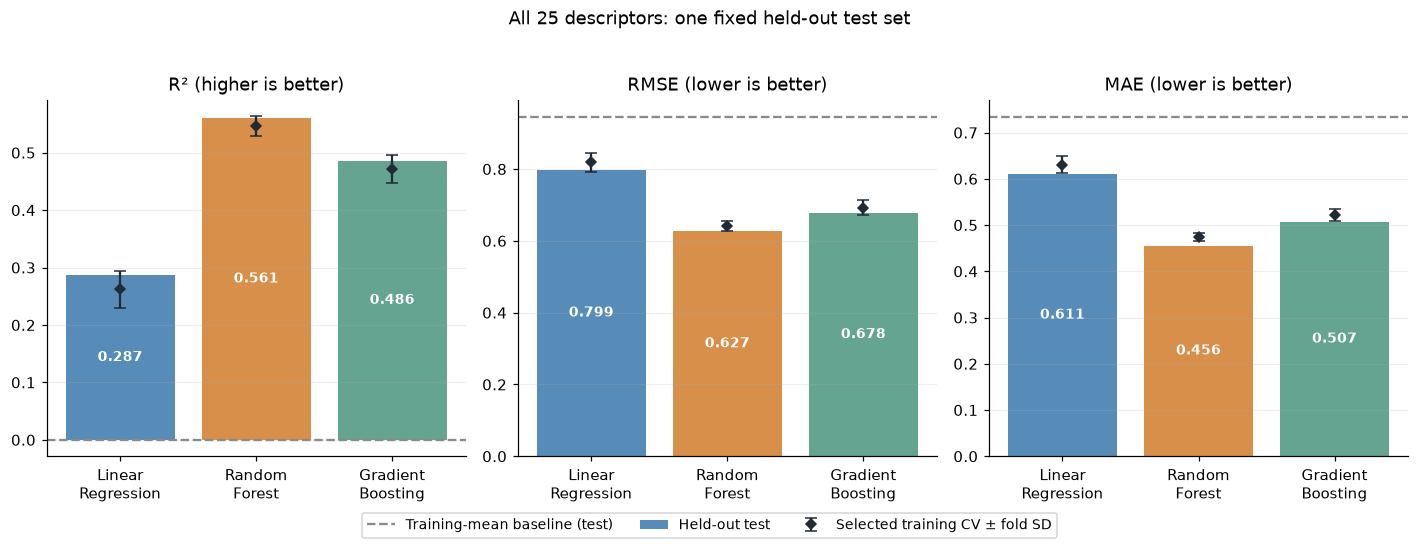

**Interpretation.** Random Forest has the lowest training CV RMSE (0.641 ± 0.015 across folds), and is selected for interpretation. Its held-out R² is 0.561, RMSE 0.627, and MAE 0.456. The lowest test RMSE belongs to Random Forest. The training-mean baseline RMSE is 0.946. These scores describe prediction of an individual toxicity record from its molecular descriptors; they do not measure the strength or direction of an HBA-specific association. Fold SD describes variation between the five validation folds and is not a confidence interval.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
colors = ['#3977AC', '#D17B2A', '#49947D']
labels = ['Linear\nRegression', 'Random\nForest', 'Gradient\nBoosting']
for ax, metric, title in zip(axes, ['r2', 'rmse', 'mae'],
                             ['R² (higher is better)', 'RMSE (lower is better)', 'MAE (lower is better)']):
    heights = full_results[f'test_{metric}'].to_numpy()
    bars = ax.bar(np.arange(3), heights, color=colors, alpha=0.85, label='Held-out test')
    ax.errorbar(np.arange(3), full_results[f'cv_{metric}_mean'],
                yerr=full_results[f'cv_{metric}_std'], fmt='D', color='#202B36',
                capsize=4, markersize=5, label='Selected training CV ± fold SD')
    ax.axhline(dummy_metrics[f'test_{metric}'], linestyle='--', color='#8A8A8A', label='Training-mean baseline (test)')
    ax.bar_label(bars, fmt='%.3f', label_type='center', color='white', fontweight='bold', fontsize=9)
    ax.set(xticks=np.arange(3), xticklabels=labels, title=title)
    ax.grid(axis='y', alpha=0.2)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=9)
fig.suptitle('All 25 descriptors: one fixed held-out test set', y=1.03)
save_plot(fig, 'ml_model_comparison.png')
interpret(f"{best_name} has the lowest training CV RMSE ({best_row['cv_rmse_mean']:.3f} ± "
          f"{best_row['cv_rmse_std']:.3f} across folds), and is selected for interpretation. "
          f"Its held-out R² is {best_row['test_r2']:.3f}, RMSE {best_row['test_rmse']:.3f}, and "
          f"MAE {best_row['test_mae']:.3f}. The lowest test RMSE belongs to {test_best_name}. "
          f"The training-mean baseline RMSE is {dummy_metrics['test_rmse']:.3f}. "
          "These scores describe prediction of an individual toxicity record from its molecular descriptors; "
          "they do not measure the strength or direction of an HBA-specific association. "
          "Fold SD describes variation between the five validation folds and is not a confidence interval.")

## 5. Does acceptor count add predictive information?

Compare the same three model families using HBA alone, all 25 descriptors, and the
24 remaining descriptors. The folds, test records, preprocessing rules and tuning
criterion are fixed across comparisons. Other descriptors can act as HBA proxies,
so this is an incremental predictive-value test, not a chemical intervention.

For each family, report **ΔRMSE = RMSE(without HBA) − RMSE(all)**: positive means
the explicit HBA column helped. A paired bootstrap resamples held-out **SMILES groups**
1,000 times and evaluates both fixed fitted models on each identical resample.
The percentile 95% interval reflects test-sample uncertainty conditional on this split
and fitted models; it does not include retraining or hyperparameter-selection uncertainty.
These are exploratory intervals, with no multiplicity-adjusted hypothesis claim.

,feature_set,model,test_r2,test_rmse,test_mae,cv_rmse_mean,cv_rmse_std
0,HBA only,Linear Regression,0.0613,0.9163,0.7103,0.9252,0.0136
1,HBA only,Random Forest,0.0638,0.9150,0.7104,0.9160,0.0169
2,HBA only,Gradient Boosting,0.0676,0.9132,0.7092,0.9153,0.0171
3,All descriptors,Linear Regression,0.2869,0.7986,0.6109,0.8183,0.0257
4,All descriptors,Random Forest,0.5605,0.6269,0.4557,0.6414,0.0152
5,All descriptors,Gradient Boosting,0.4860,0.6780,0.5072,0.6919,0.0210
6,Without HBA,Linear Regression,0.2879,0.7980,0.6106,0.8186,0.0259
7,Without HBA,Random Forest,0.5595,0.6277,0.4568,0.6427,0.0156
8,Without HBA,Gradient Boosting,0.4873,0.6771,0.5051,0.6927,0.0218


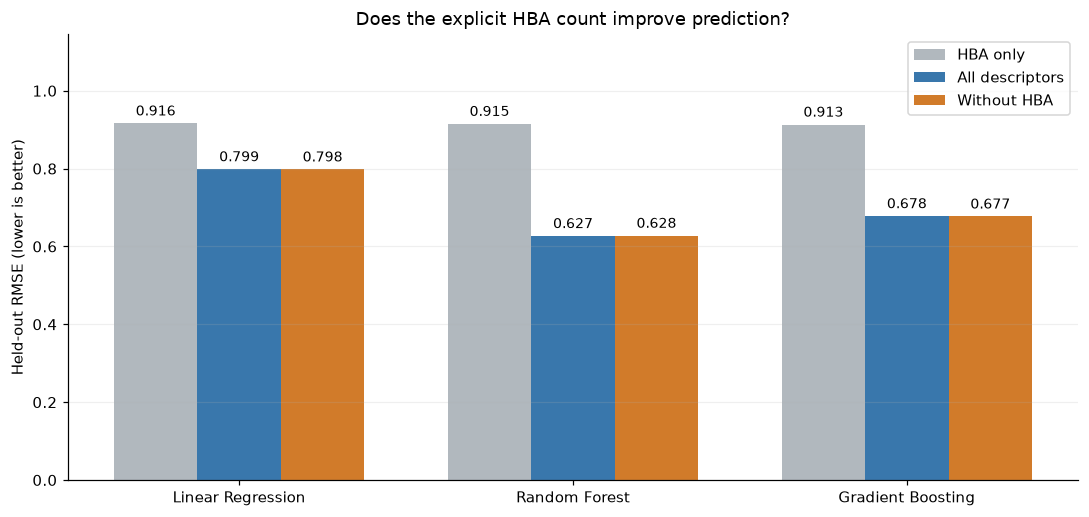

,model,delta_test_rmse_without_minus_all,ci95_low,ci95_high,delta_cv_rmse_without_minus_all,bootstrap_repeats
0,Linear Regression,-0.00056,-0.00290,0.00142,0.00031,1000
1,Random Forest,0.00073,-0.00357,0.00470,0.00127,1000
2,Gradient Boosting,-0.00088,-0.00383,0.00212,0.00075,1000


**Interpretation.** For Random Forest, HBA alone has test R²=0.064, versus 0.561 with all descriptors and 0.559 without HBA. Removing HBA changes RMSE by +0.0007 (paired 95% interval -0.0036 to +0.0047). The interval spans zero, so this holdout does not resolve a clear incremental benefit. Compare all three families above: the answer can depend on model form. A small change can mean that correlated descriptors already supply similar information, not that hydrogen bonding has no chemical relevance.

In [7]:
display(comparison[['feature_set', 'model', 'test_r2', 'test_rmse', 'test_mae',
                    'cv_rmse_mean', 'cv_rmse_std']].round(4))
fig, ax = plt.subplots(figsize=(10, 4.8))
positions = np.arange(len(model_specs))
for j, (set_name, color) in enumerate(zip(feature_sets, ['#B1B8BE', '#3977AC', '#D17B2A'])):
    rows = comparison.loc[comparison['feature_set'].eq(set_name)].set_index('model').loc[list(model_specs)]
    bars = ax.bar(positions + (j - 1) * 0.25, rows['test_rmse'], width=0.25,
                  label=set_name, color=color)
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set(xticks=positions, xticklabels=list(model_specs), ylabel='Held-out RMSE (lower is better)',
       title='Does the explicit HBA count improve prediction?')
ax.legend(loc='upper right')
ax.set_ylim(0, comparison['test_rmse'].max() * 1.25)
ax.grid(axis='y', alpha=0.2)
save_plot(fig, 'ml_hba_ablation.png')

# Use the same group bootstrap weights for every paired model comparison.
test_codes, unique_test_groups = pd.factorize(test_groups, sort=True)
n_groups = len(unique_test_groups)
group_sizes = np.bincount(test_codes)
rng = np.random.default_rng(SEED)
bootstrap_weights = rng.multinomial(n_groups, np.full(n_groups, 1 / n_groups), size=1000)
bootstrap_sizes = bootstrap_weights @ group_sizes
ablation_rows = []
for model_name in model_specs:
    squared_full = (y_test.to_numpy() - predictions[f'All descriptors | {model_name}']) ** 2
    squared_without = (y_test.to_numpy() - predictions[f'Without HBA | {model_name}']) ** 2
    full_group_error = np.bincount(test_codes, weights=squared_full)
    without_group_error = np.bincount(test_codes, weights=squared_without)
    bootstrap_delta = (np.sqrt((bootstrap_weights @ without_group_error) / bootstrap_sizes)
                       - np.sqrt((bootstrap_weights @ full_group_error) / bootstrap_sizes))
    low, high = np.quantile(bootstrap_delta, [0.025, 0.975])
    rows = comparison.loc[comparison['model'].eq(model_name)].set_index('feature_set')
    ablation_rows.append({'model': model_name,
                          'delta_test_rmse_without_minus_all': rows.loc['Without HBA', 'test_rmse'] - rows.loc['All descriptors', 'test_rmse'],
                          'ci95_low': low, 'ci95_high': high,
                          'delta_cv_rmse_without_minus_all': rows.loc['Without HBA', 'cv_rmse_mean'] - rows.loc['All descriptors', 'cv_rmse_mean'],
                          'bootstrap_repeats': 1000})
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(RESULTS / 'ml_hba_ablation_uncertainty.csv', index=False)
display(ablation.round(5))
best_ablation = ablation.set_index('model').loc[best_name]
best_variants = comparison.loc[comparison['model'].eq(best_name)].set_index('feature_set')
interval_comment = ('The interval spans zero, so this holdout does not resolve a clear incremental benefit.'
                    if best_ablation['ci95_low'] <= 0 <= best_ablation['ci95_high']
                    else 'The interval excludes zero for these fixed models; its sign indicates the direction, conditional on this split.')
interpret(f"For {best_name}, HBA alone has test R²={best_variants.loc['HBA only', 'test_r2']:.3f}, "
          f"versus {best_variants.loc['All descriptors', 'test_r2']:.3f} with all descriptors and "
          f"{best_variants.loc['Without HBA', 'test_r2']:.3f} without HBA. "
          f"Removing HBA changes RMSE by {best_ablation['delta_test_rmse_without_minus_all']:+.4f} "
          f"(paired 95% interval {best_ablation['ci95_low']:+.4f} to {best_ablation['ci95_high']:+.4f}). "
          + interval_comment + ' Compare all three families above: the answer can depend on model form. '
          'A small change can mean that correlated descriptors already supply similar information, '
          'not that hydrogen bonding has no chemical relevance.')

## 6. Held-out permutation importance

For the model family selected by all-descriptor training CV, shuffle one test-set
descriptor at a time, repeating 30 times with seed 42. The score decrease is the
**drop in test R²**; larger positive values mean the fitted model relied more on
that descriptor. Negative values mean shuffling happened to improve this score.
The bars below show mean ± permutation SD, not a confidence interval or a p-value.

Permutation importance is conditional on the fitted model and its other predictors.
Correlated descriptors can share importance, and shuffling can create combinations
that real molecules do not have. Importance supplies neither an association's direction
nor a causal effect. The ablation comparison additionally allows a model to refit
without HBA, so its size need not match the permutation result.

,rank,descriptor,mean_drop_test_r2,permutation_sd
0,1,MaxPartialCharge,0.13792,0.00652
1,2,SlogP_VSA12,0.10260,0.00863
2,3,NumHeteroatoms,0.07999,0.00618
3,4,MinEStateIndex,0.06904,0.00563
4,5,MinPartialCharge,0.06562,0.00639
5,6,BertzCT,0.05390,0.00466
6,7,Chi3v,0.05167,0.00482
7,8,SMR_VSA10,0.04525,0.00549
8,9,HeavyAtomMolWt,0.03332,0.00293
9,10,SlogP_VSA5,0.02641,0.00332


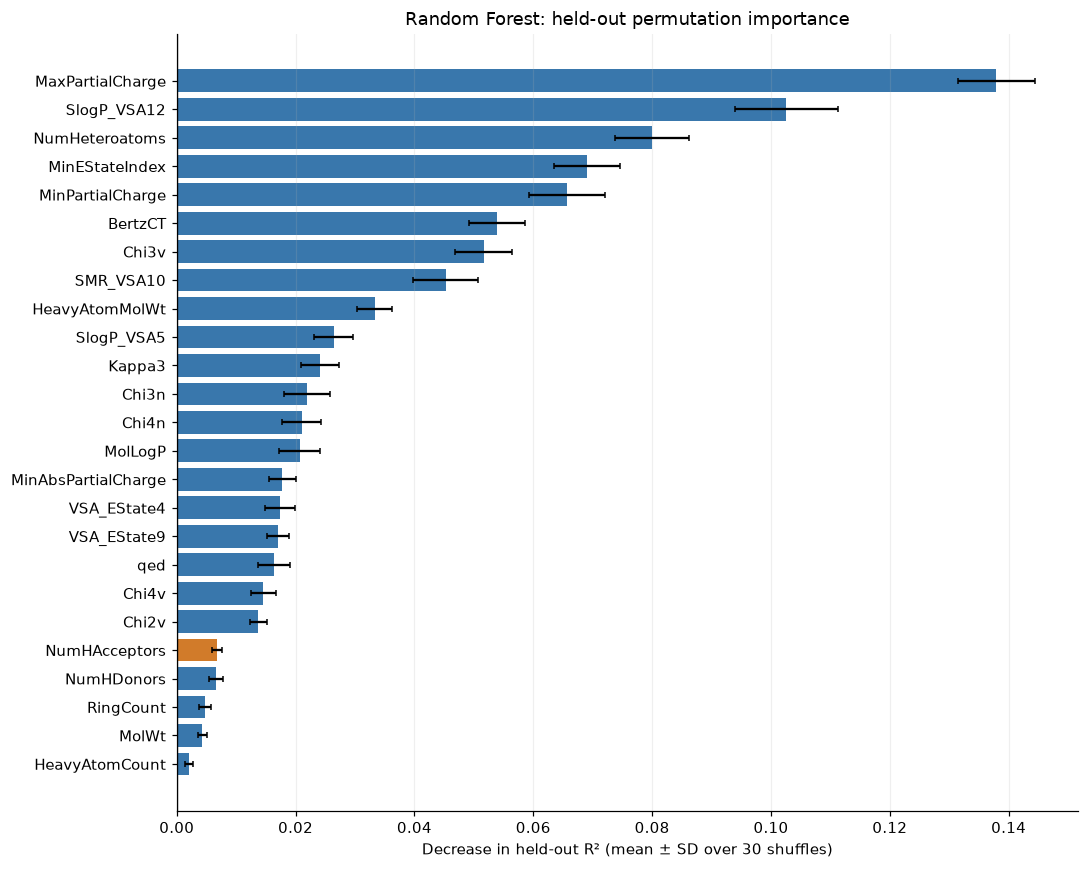

**Interpretation.** NumHAcceptors ranks 21 of 25, with mean R² drop 0.0068 ± 0.0008 (shuffle SD). MolWt ranks 24 (drop 0.0043); MolLogP ranks 14 (drop 0.0207). The five highest-ranked descriptors are MaxPartialCharge, SlogP_VSA12, NumHeteroatoms, MinEStateIndex, MinPartialCharge. These rankings describe this model's reliance on the columns. A weak positive marginal Spearman correlation and a positive coefficient adjusted for only MolWt and MolLogP can coexist with modest incremental value after many overlapping descriptors are included. Neither a high importance nor a low importance establishes a chemical cause or its absence.

In [8]:
with threadpool_limits(limits=1):
    perm = permutation_importance(best_model, X_test, y_test, scoring='r2',
                                  n_repeats=30, random_state=SEED, n_jobs=N_JOBS)
importance = pd.DataFrame({'descriptor': FEATURES, 'mean_drop_test_r2': perm.importances_mean,
                           'permutation_sd': perm.importances_std})
importance = importance.sort_values('mean_drop_test_r2', ascending=False).reset_index(drop=True)
importance.insert(0, 'rank', np.arange(1, len(importance) + 1))
importance.to_csv(RESULTS / 'ml_permutation_importance.csv', index=False)
display(importance.round(5))
shown = importance.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(shown['descriptor'], shown['mean_drop_test_r2'], xerr=shown['permutation_sd'],
        color=['#D17B2A' if c == 'NumHAcceptors' else '#3977AC' for c in shown['descriptor']],
        capsize=2)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Decrease in held-out R² (mean ± SD over 30 shuffles)',
       title=f'{best_name}: held-out permutation importance')
ax.grid(axis='x', alpha=0.2)
save_plot(fig, 'ml_permutation_importance.png')

hba_importance = importance.set_index('descriptor').loc['NumHAcceptors']
mass_importance = importance.set_index('descriptor').loc['MolWt']
logp_importance = importance.set_index('descriptor').loc['MolLogP']
leading_features = ', '.join(importance.head(5)['descriptor'])
interpret(f"NumHAcceptors ranks {int(hba_importance['rank'])} of {len(FEATURES)}, with mean R² drop "
          f"{hba_importance['mean_drop_test_r2']:.4f} ± {hba_importance['permutation_sd']:.4f} (shuffle SD). "
          f"MolWt ranks {int(mass_importance['rank'])} (drop {mass_importance['mean_drop_test_r2']:.4f}); "
          f"MolLogP ranks {int(logp_importance['rank'])} (drop {logp_importance['mean_drop_test_r2']:.4f}). "
          f"The five highest-ranked descriptors are {leading_features}. "
          "These rankings describe this model's reliance on the columns. A weak positive marginal "
          "Spearman correlation and a positive coefficient adjusted for only MolWt and MolLogP "
          "can coexist with modest incremental value after many overlapping descriptors are included. "
          "Neither a high importance nor a low importance establishes a chemical cause or its absence.")

**Chemical reading:** LogP is more influential than HBA in this forest, while the MolWt column is less influential. HeavyAtomMolWt ranks ninth and carries overlapping mass information, so MolWt's low individual rank does not show that molecular mass is irrelevant. Charge, electronic environment and surface-area descriptors lead the ranking.

## 7. Prediction diagnostics and limits

Inspect prediction error across the observed toxicity range, the training/test gap,
and performance when each test SMILES contributes one aggregated observation. The latter
uses mean prediction and median observed toxicity within a SMILES and is a sensitivity
with a different unit of analysis; it does not replace the primary record-level scores.
No observation is removed and no model is changed after these checks.

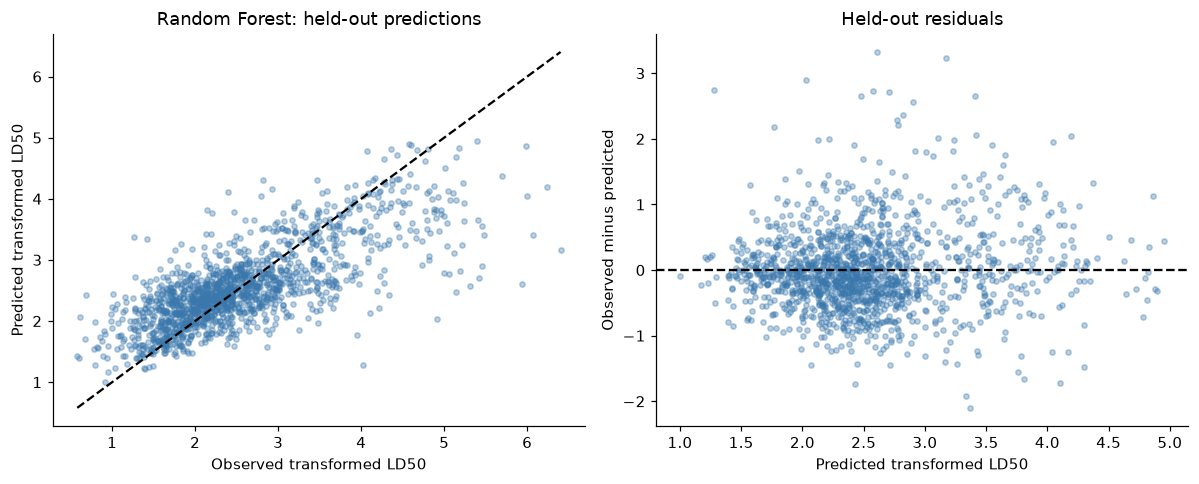

,n,observed_mean,mean_residual,rmse
observed_quartile,,,,
"(0.579, 1.862]",370,1.5359,-0.4701,0.6195
"(1.862, 2.358]",372,2.1204,-0.2021,0.3872
"(2.358, 2.999]",367,2.6365,0.0630,0.4238
"(2.999, 6.402]",370,3.8662,0.5993,0.9265


One aggregated observation per held-out SMILES: {'n_smiles': 1469, 'r2': 0.5616427451322048, 'rmse': 0.627115620058843, 'mae': 0.45567863342950066}


**Interpretation.** Training RMSE is 0.234, compared with held-out RMSE 0.627; a lower training error reflects fit to familiar compounds and should not be reported as generalisation performance. The one-SMILES sensitivity gives R²=0.562 and RMSE=0.627. Positive residuals mean toxicity was underestimated. Errors grouped by the observed outcome show where prediction is difficult, but are not a calibration test: conditioning on observed extremes itself produces a tendency toward the middle. These descriptive checks do not establish safety for individual compounds or transportability to other assays or species.

In [9]:
best_prediction = predictions[f'All descriptors | {best_name}'].to_numpy()
test_residual = y_test.to_numpy() - best_prediction
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test, best_prediction, s=12, alpha=0.35, color='#3977AC')
limits = [min(y_test.min(), best_prediction.min()), max(y_test.max(), best_prediction.max())]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlabel='Observed transformed LD50', ylabel='Predicted transformed LD50',
            title=f'{best_name}: held-out predictions')
axes[1].scatter(best_prediction, test_residual, s=12, alpha=0.35, color='#3977AC')
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(xlabel='Predicted transformed LD50', ylabel='Observed minus predicted',
            title='Held-out residuals')
save_plot(fig, 'ml_prediction_diagnostics.png')

diagnostic_data = pd.DataFrame({'SMILES': test_groups.to_numpy(), 'observed': y_test.to_numpy(),
                                'predicted': best_prediction, 'residual': test_residual})
diagnostic_data['observed_quartile'] = pd.qcut(diagnostic_data['observed'], 4, duplicates='drop')
error_by_quartile = diagnostic_data.groupby('observed_quartile', observed=True).agg(
    n=('observed', 'size'), observed_mean=('observed', 'mean'),
    mean_residual=('residual', 'mean'),
    rmse=('residual', lambda r: np.sqrt(np.mean(r ** 2))))
error_by_quartile.to_csv(RESULTS / 'ml_error_by_toxicity_quartile.csv')
per_smiles_test = diagnostic_data.groupby('SMILES').agg(observed=('observed', 'median'),
                                                       predicted=('predicted', 'mean'))
group_metrics = {'n_smiles': len(per_smiles_test),
                 'r2': r2_score(per_smiles_test['observed'], per_smiles_test['predicted']),
                 'rmse': root_mean_squared_error(per_smiles_test['observed'], per_smiles_test['predicted']),
                 'mae': mean_absolute_error(per_smiles_test['observed'], per_smiles_test['predicted'])}
display(error_by_quartile.round(4))
print('One aggregated observation per held-out SMILES:', group_metrics)
interpret(f"Training RMSE is {best_row['train_rmse']:.3f}, compared with held-out RMSE "
          f"{best_row['test_rmse']:.3f}; a lower training error reflects fit to familiar compounds "
          "and should not be reported as generalisation performance. "
          f"The one-SMILES sensitivity gives R²={group_metrics['r2']:.3f} and RMSE={group_metrics['rmse']:.3f}. "
          "Positive residuals mean toxicity was underestimated. Errors grouped by the observed outcome "
          "show where prediction is difficult, but are not a calibration test: conditioning on observed "
          "extremes itself produces a tendency toward the middle. These descriptive checks do not establish "
          "safety for individual compounds or transportability to other assays or species.")

**Diagnostic reading:** The forest's training RMSE (0.234) is much smaller than its test RMSE (0.627), indicating overfitting relative to its training performance. Nevertheless, its similar CV and held-out errors support the reported internal predictive performance. The prediction plot shows underestimation of many highly toxic records; the model should not be treated as a precise individual-compound forecast.

## 8. Research conclusion

The following summary is populated from this execution, so its numbers match the saved tables.

In [10]:
interpret(f"**Association and significance:** In {len(df):,} records, the original two-sided Spearman "
          f"test finds a weak positive HBA-toxicity association (rho={rho['estimate']:.3f}, "
          f"p={rho['p_two_sided']:.3e}). This rejects the no-association null under the test assumptions "
          "and supports the direction of H1, while the small effect size prevents a claim of a strong relationship. "
          f"The association remains positive after adjustment for MolWt and MolLogP (coefficient "
          f"{adjusted['estimate']:.3f}, 95% CI {adjusted['ci95_low']:.3f}–{adjusted['ci95_high']:.3f}). "
          f"**Prediction:** The CV-selected model is {best_name}, with held-out R²={best_row['test_r2']:.3f}, "
          f"RMSE={best_row['test_rmse']:.3f} and MAE={best_row['test_mae']:.3f}. "
          f"For this family, HBA alone gives R²={best_variants.loc['HBA only', 'test_r2']:.3f}. "
          f"**Incremental information:** Removing HBA changes test RMSE by "
          f"{best_ablation['delta_test_rmse_without_minus_all']:+.4f} (95% paired interval "
          f"{best_ablation['ci95_low']:+.4f} to {best_ablation['ci95_high']:+.4f}). "
          + interval_comment + ' '
          f"**Importance:** HBA ranks {int(hba_importance['rank'])}/{len(FEATURES)} by test permutation importance. "
          "This is model reliance, not statistical significance or an effect's direction. "
          "**Chemistry conclusion:** Compounds with more acceptors tend on average to have higher acute "
          "toxicity scores in this dataset, but acceptor count alone is a weak guide to an individual "
          "compound's toxicity. Size, lipophilicity and other molecular properties jointly carry predictive "
          "information. Correlated properties, the observational design, assay variation and incomplete "
          "control of confounding prevent a causal interpretation. Machine learning supports a qualified "
          "association, not a claim that adding acceptors causes toxicity.")

**Interpretation.** **Association and significance:** In 7,388 records, the original two-sided Spearman test finds a weak positive HBA-toxicity association (rho=0.252, p=1.450e-107). This rejects the no-association null under the test assumptions and supports the direction of H1, while the small effect size prevents a claim of a strong relationship. The association remains positive after adjustment for MolWt and MolLogP (coefficient 0.083, 95% CI 0.065–0.102). **Prediction:** The CV-selected model is Random Forest, with held-out R²=0.561, RMSE=0.627 and MAE=0.456. For this family, HBA alone gives R²=0.064. **Incremental information:** Removing HBA changes test RMSE by +0.0007 (95% paired interval -0.0036 to +0.0047). The interval spans zero, so this holdout does not resolve a clear incremental benefit. **Importance:** HBA ranks 21/25 by test permutation importance. This is model reliance, not statistical significance or an effect's direction. **Chemistry conclusion:** Compounds with more acceptors tend on average to have higher acute toxicity scores in this dataset, but acceptor count alone is a weak guide to an individual compound's toxicity. Size, lipophilicity and other molecular properties jointly carry predictive information. Correlated properties, the observational design, assay variation and incomplete control of confounding prevent a causal interpretation. Machine learning supports a qualified association, not a claim that adding acceptors causes toxicity.

## 9. Reproducibility and output checks

Run all cells in order, or from the repository root run
`.\.venv\Scripts\python.exe src/machine_learning.py --all` to execute both notebooks.
Results are in `results/ml_*.csv` and `results/association_sensitivity.csv`; new figures
use the `ml_` prefix. Existing plots are not overwritten. The JSON manifest records
input hashes, versions, feature sets, split sizes, model selection and diagnostic summaries.
The split table uses zero-based **processed CSV row indices**, not CSV line numbers.

Method references: [scikit-learn grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data)
and [permutation importance and correlated features](https://scikit-learn.org/stable/modules/permutation_importance.html).
The code uses the installed scikit-learn version recorded below.

In [11]:
versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'nbclient', 'nbformat']}
metadata = {
    'seed': SEED, 'python_version': platform.python_version(), 'package_versions': versions,
    'input_sha256': input_hashes, 'feature_sets': feature_sets,
    'grouping': 'Exact recorded SMILES; no canonicalisation or scaffold split',
    'train_records': len(train_idx), 'test_records': len(test_idx),
    'train_smiles': int(train_groups.nunique()), 'test_smiles': int(test_groups.nunique()),
    'training_cv': '5 shuffled GroupKFold folds; selection CV, not nested CV',
    'selection_metric': 'minimum all-descriptor training CV RMSE',
    'cv_selected_model': best_name, 'lowest_test_rmse_model': test_best_name,
    'training_mean_baseline_test': dummy_metrics, 'test_one_smiles_sensitivity': group_metrics,
    'permutation_score': 'drop in held-out R2', 'permutation_repeats': 30,
    'paired_bootstrap_repeats': 1000, 'adjusted_hba_vif': hba_vif,
    'cooks_screening_threshold': 4 / len(complete), 'cooks_flagged_records': int(influential.sum()),
}
(RESULTS / 'ml_run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

# Check exported numbers against fitted predictions, not just copied table values.
saved_predictions = pd.read_csv(RESULTS / 'ml_test_predictions.csv')
saved_comparison = pd.read_csv(RESULTS / 'ml_model_comparison.csv')
for _, row in saved_comparison.iterrows():
    predicted = saved_predictions[f'{row["feature_set"]} | {row["model"]}']
    observed = saved_predictions['observed_LD50']
    assert np.isclose(r2_score(observed, predicted), row['test_r2'])
    assert np.isclose(root_mean_squared_error(observed, predicted), row['test_rmse'])
    assert np.isclose(mean_absolute_error(observed, predicted), row['test_mae'])
for (set_name, model_name), model in fitted_models.items():
    expected_medians = X_train[feature_sets[set_name]].median().to_numpy()
    np.testing.assert_allclose(model.named_steps['imputer'].statistics_, expected_medians)
for path, digest in input_hashes.items():
    assert hashlib.sha256((ROOT / path).read_bytes()).hexdigest() == digest, path
assert saved_comparison.shape[0] == 9
assert len(importance) == len(FEATURES)
print('PASS: all nine metric rows reproduce from saved test predictions; fitted medians use training data.')
print('PASS: raw and processed CSV bytes unchanged; split/CV overlap checks passed above.')
print('Versions:', versions)

PASS: all nine metric rows reproduce from saved test predictions; fitted medians use training data.
PASS: raw and processed CSV bytes unchanged; split/CV overlap checks passed above.
Versions: {'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'nbclient': '0.11.0', 'nbformat': '5.11.1'}
